**Smoke detection version af `CropCalculatorDecisionTree.ipynb`.** Koden er den samme som originalen; kun data-stien og udvælgelsen af features/target er ændret. Datasæt: `data/smoke_detection_iot.csv`. `Unnamed: 0` (index), `UTC` (tidsstempel) og `CNT` (tæller) er droppet. Features = kun `Temperature[C]`, `Humidity[%]` og `PM2.5` (de tre sensorer i Forest Fire Sensor Network-projektet; alle numeriske, så `cat_attribs` er tom), target = `Fire Alarm`. Split stratificeres på `Fire Alarm` i stedet for `Entity`. `np.log1p` bruges på `PM2.5` (meget skæv fordeling) i stedet for `Nitrogen_fertilizer_use`.

**Note:** `Fire Alarm` er binær (0/1), men modellen er stadig en *regressor* ligesom i originalen. Forudsigelserne er derfor et tal (ca. mellem 0 og 1), og RMSE/MSE/R2/MAE måler hvor tæt det tal er på 0/1. Det er ikke en klassifikations-accuracy.

In [1]:
import warnings
warnings.filterwarnings('ignore')
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns
import numpy as np
import plotly.express as px
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import SGDRegressor






In [2]:
#df=pd.read_csv("data/cerealCrop.csv")
df=pd.read_csv("data/smoke_detection_iot.csv")
df = df.drop(columns=["Unnamed: 0", "UTC", "CNT"]) # index, tidsstempel og tæller er ikke features
df['PM2.5'] = np.log1p(df['PM2.5'])

df.head()


,Temperature[C],Humidity[%],TVOC[ppb],eCO2[ppm],Raw H2,Raw Ethanol,Pressure[hPa],PM1.0,PM2.5,NC0.5,NC1.0,NC2.5,Fire Alarm
0,20.000,57.36,0,400,12306,18520,939.735,0.0,0.0,0.0,0.0,0.0,0
1,20.015,56.67,0,400,12345,18651,939.744,0.0,0.0,0.0,0.0,0.0,0
2,20.029,55.96,0,400,12374,18764,939.738,0.0,0.0,0.0,0.0,0.0,0
3,20.044,55.28,0,400,12390,18849,939.736,0.0,0.0,0.0,0.0,0.0,0
4,20.059,54.69,0,400,12403,18921,939.744,0.0,0.0,0.0,0.0,0.0,0


In [3]:
df.shape

(62630, 13)

In [4]:
#list(df.columns)


In [5]:
#train_set, test_set = train_test_split(df, test_size=0.2, random_state=42)

#attributes = ["Yield", "Crop_Type", "Fertilizer_Type", "Region", 
#              "N", "P", "K", "pH", "Temperature", "Rainfall"]

strat_train_set, strat_test_set = train_test_split(
    df, 
    test_size=0.2, 
    stratify=df["Fire Alarm"], # Vi sikrer balancen mellem alarm / ikke alarm
    random_state=42
)


attributes = ["Temperature[C]", "Humidity[%]", "PM2.5", "Fire Alarm"]

train_set = strat_train_set[attributes].copy()
test_set = strat_test_set[attributes].copy()

In [6]:
corr_matrix = train_set.corr(numeric_only=True)
print(corr_matrix["Fire Alarm"].sort_values(ascending=False))

Fire Alarm        1.000000
Humidity[%]       0.399020
PM2.5            -0.049535
Temperature[C]   -0.164362
Name: Fire Alarm, dtype: float64


In [7]:
train_set.head()

,Temperature[C],Humidity[%],PM2.5,Fire Alarm
17799,17.422,51.93,1.108563,1
6596,-6.695,55.87,0.506818,1
46619,26.950,47.74,1.156881,1
41355,24.850,52.23,1.000632,1
57343,22.649,40.51,1.098612,0


In [8]:
train_clean = train_set.dropna(subset=["Fire Alarm"]) #y true

X_valueFromMatrix = train_clean.drop("Fire Alarm", axis=1)
Yield_labels = train_clean["Fire Alarm"].copy()


num_attribs = ["Temperature[C]", "Humidity[%]", "PM2.5"]

cat_attribs = [] # ingen kategoriske kolonner i dette datasæt



num_pipeline = make_pipeline(
 SimpleImputer(strategy="median"),
    StandardScaler())

cat_pipeline = make_pipeline(
 SimpleImputer(strategy="most_frequent"),
 OneHotEncoder(handle_unknown="ignore")) #Note skal vi lige undersøge hvad betyder 

#print(X_train_prepared.shape)


preprocessing = ColumnTransformer([
 ("num", num_pipeline, num_attribs),
 ("cat", cat_pipeline, cat_attribs),
])


X_train_prepared = preprocessing.fit_transform(X_valueFromMatrix)

print(X_train_prepared.shape)




(50104, 3)


In [9]:
#tree_reg = make_pipeline(preprocessing, LinearRegression())
#tree_reg.fit(X_valueFromMatrix, Yield_labels)
tree_reg = make_pipeline(preprocessing, DecisionTreeRegressor(random_state=42))
tree_reg.fit(X_valueFromMatrix, Yield_labels)

#tree_reg = make_pipeline(preprocessing,SGDRegressor(max_iter=1000, tol=1e-3, penalty=None, eta0=0.00001, random_state=42))
#tree_reg.fit(X_valueFromMatrix, Yield_labels)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('decisiontreeregressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](3,)","['Temperature[C]','Humidity[%]','PM2.5']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,3
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatena

In [10]:
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

yield_predictions = tree_reg.predict(X_valueFromMatrix)

tree_mse = mean_squared_error(Yield_labels, yield_predictions)

tree_rmse = np.sqrt(tree_mse)

print("Decision Tree præstation på træningsdata:")
print(f"Modellens gennemsnitlige fejl (RMSE): {tree_rmse}")
print(f"Modellens MSE: {tree_mse}")
tree_r2 = r2_score(Yield_labels, yield_predictions)
print(f"Modellens R2 score: {tree_r2}")
mae = np.mean(np.abs(Yield_labels - yield_predictions))
print(f"Modellens MAE: {mae}")

Decision Tree præstation på træningsdata:
Modellens gennemsnitlige fejl (RMSE): 0.0
Modellens MSE: 0.0
Modellens R2 score: 1.0
Modellens MAE: 0.0


In [11]:
tree_rmses = -cross_val_score(tree_reg, X_valueFromMatrix, Yield_labels,
 scoring="neg_root_mean_squared_error", cv=10)

pd.Series(tree_rmses).describe()

count    10.000000
mean      0.122958
std       0.005762
min       0.113013
25%       0.120710
50%       0.121931
75%       0.124961
max       0.134030
dtype: float64

In [12]:
print(Yield_labels.mean())


0.7146335621906434


In [13]:
#print(DecisionTreeRegressor().get_params())


In [14]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline


full_pipeline = Pipeline([
 ("preprocessing", preprocessing),
 ("decision_tree", DecisionTreeRegressor(random_state=42)),
])
param_grid = [
    {
        'decision_tree__max_depth': [None, 10, 20, 30],
        'decision_tree__min_samples_split': [2, 5, 10],
        'decision_tree__min_samples_leaf': [1, 2, 4]
    },
]
grid_search = GridSearchCV(full_pipeline, param_grid, cv=5,
 scoring='neg_root_mean_squared_error')
grid_search.fit(X_valueFromMatrix, Yield_labels)


cv_res = pd.DataFrame(grid_search.cv_results_)
cv_res.sort_values(by="mean_test_score", ascending=False, inplace=True)



In [15]:

columns_to_show = [
    "param_decision_tree__max_depth",
    "param_decision_tree__min_samples_leaf",
    "mean_test_score",
] 

cv_res.head() 
#print(cv_res[columns_to_show].head())
#final_predictions = final_model.predict(X_test) # (flyttet: final_model defineres først i næste celle)


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_decision_tree__max_depth,param_decision_tree__min_samples_leaf,param_decision_tree__min_samples_split,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
23,0.064233,0.002874,0.002661,0.000036,20,2,10,"{'decision_tree__max_depth': 20, 'decision_tre...",-0.109231,-0.117050,-0.115373,-0.117787,-0.117048,-0.115298,0.003135,1
5,0.066639,0.002179,0.002759,0.000127,None,2,10,"{'decision_tree__max_depth': None, 'decision_t...",-0.109563,-0.115547,-0.116155,-0.117343,-0.118263,-0.115374,0.003054,2
32,0.063351,0.002858,0.002672,0.000079,30,2,10,"{'decision_tree__max_depth': 30, 'decision_tre...",-0.109563,-0.115547,-0.116155,-0.117343,-0.118263,-0.115374,0.003054,2
3,0.066766,0.003113,0.003082,0.000309,None,2,2,"{'decision_tree__max_depth': None, 'decision_t...",-0.111288,-0.117633,-0.117657,-0.115637,-0.118074,-0.116058,0.002531,4
30,0.063946,0.002454,0.002707,0.000098,30,2,2,"{'decision_tree__max_depth': 30, 'decision_tre...",-0.111288,-0.117633,-0.117657,-0.115637,-0.118074,-0.116058,0.002531,4


In [16]:
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
test_clean = test_set.dropna(subset=["Fire Alarm"])

X_test = test_clean.drop("Fire Alarm", axis=1)
y_test = test_clean["Fire Alarm"].copy()

final_model = grid_search.best_estimator_


final_predictions = final_model.predict(X_test)

final_mse = mean_squared_error(y_test, final_predictions)
final_rmse = np.sqrt(final_mse)

print("Decision Tree Regressor")
print(f"Din endelige test-MSE er: {final_mse:.4f}")
print(f"Din endelige test-RMSE er: {final_rmse:.4f}")
final_r2 = r2_score(y_test, final_predictions)
print(f"Din endelige test-R2 score er: {final_r2:.4f}")
final_mae = mean_absolute_error(y_test, final_predictions)
print(f"Din endelige test-MAE er: {final_mae:.4f}")


Decision Tree Regressor
Din endelige test-MSE er: 0.0131
Din endelige test-RMSE er: 0.1144
Din endelige test-R2 score er: 0.9359
Din endelige test-MAE er: 0.0175


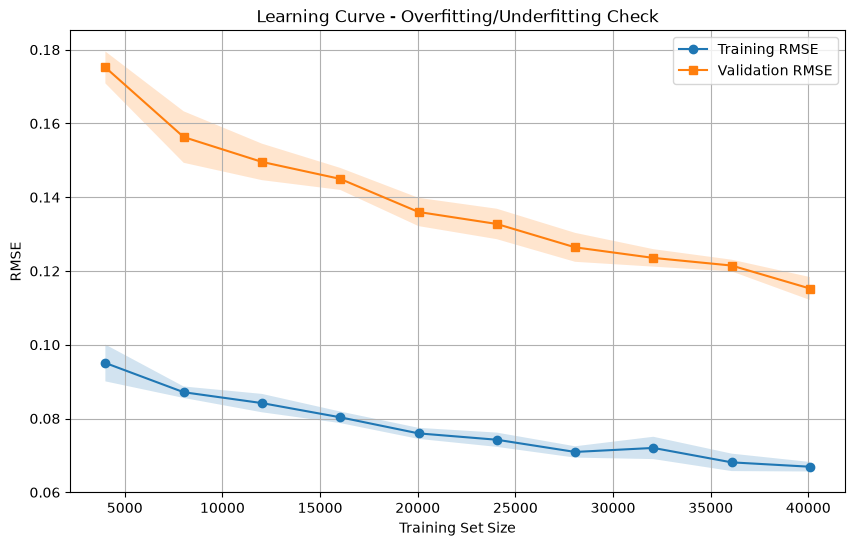

Training RMSE (final): 0.0669
Validation RMSE (final): 0.1152
Gap: 0.0483
✅ God balance - modellen generaliserer godt


In [17]:
from sklearn.model_selection import learning_curve
import matplotlib.pyplot as plt
import numpy as np

# Brug den beste model fra grid search
best_model = grid_search.best_estimator_

# Generer learning curves
train_sizes, train_scores, val_scores = learning_curve(
    best_model,
    X_valueFromMatrix,
    Yield_labels,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    train_sizes=np.linspace(0.1, 1.0, 10),
    shuffle=True,
    random_state=42
)

# Beregn gennemsnit og std
train_mean = -train_scores.mean(axis=1)  # Negativ fordi scoring er neg_rmse
train_std = train_scores.std(axis=1)
val_mean = -val_scores.mean(axis=1)
val_std = val_scores.std(axis=1)

# Plot
plt.figure(figsize=(10, 6))
plt.plot(train_sizes, train_mean, label="Training RMSE", marker='o')
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.2)
plt.plot(train_sizes, val_mean, label="Validation RMSE", marker='s')
plt.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.2)
plt.xlabel("Training Set Size")
plt.ylabel("RMSE")
plt.title("Learning Curve - Overfitting/Underfitting Check")
plt.legend()
plt.grid(True)
plt.show()

# Diagnostik
print(f"Training RMSE (final): {train_mean[-1]:.4f}")
print(f"Validation RMSE (final): {val_mean[-1]:.4f}")
print(f"Gap: {(val_mean[-1] - train_mean[-1]):.4f}")

if val_mean[-1] - train_mean[-1] > 0.15:
    print("⚠️ Tegn på OVERFITTING - validation fejl meget højere end training")
elif train_mean[-1] > 1.0:
    print("⚠️ Tegn på UNDERFITTING - begge fejl høje")
else:
    print("✅ God balance - modellen generaliserer godt")